In [1]:
using Pkg
Pkg.resolve()
Pkg.instantiate()

using FastNCG, Random, LinearAlgebra

     Project No packages added to or removed from `~/codes/Julia/MyPack/FastNCG/Project.toml`
    Manifest No packages added to or removed from `~/codes/Julia/MyPack/FastNCG/Manifest.toml`


FastNCG: 50/500 runs, latest status=first_order, |g|=6.444e-20
FastNCG: 100/500 runs, latest status=first_order, |g|=3.140e-21
FastNCG: 150/500 runs, latest status=first_order, |g|=1.799e-16
FastNCG: 200/500 runs, latest status=first_order, |g|=7.499e-20
FastNCG: 250/500 runs, latest status=first_order, |g|=2.197e-19
FastNCG: 300/500 runs, latest status=first_order, |g|=1.240e-18
FastNCG: 350/500 runs, latest status=first_order, |g|=4.241e-18
FastNCG: 400/500 runs, latest status=first_order, |g|=1.768e-19
FastNCG: 450/500 runs, latest status=first_order, |g|=9.359e-16
FastNCG: 500/500 runs, latest status=first_order, |g|=1.882e-17
FastNCG strongly convex chain experiment
d=100, phi=4.0, nu=0.01, trials=500, seed=42
x0=0.1*randn(MersenneTwister(seed),d); independent draws, no normalization
gradient tolerance=1.0e-14, max_iter=500
solver_kwargs=NamedTuple() (unspecified options use FastNCGSolver defaults)
converged=500/500
finite positive error pairs=5002, excluded=0
log base=e, horizont

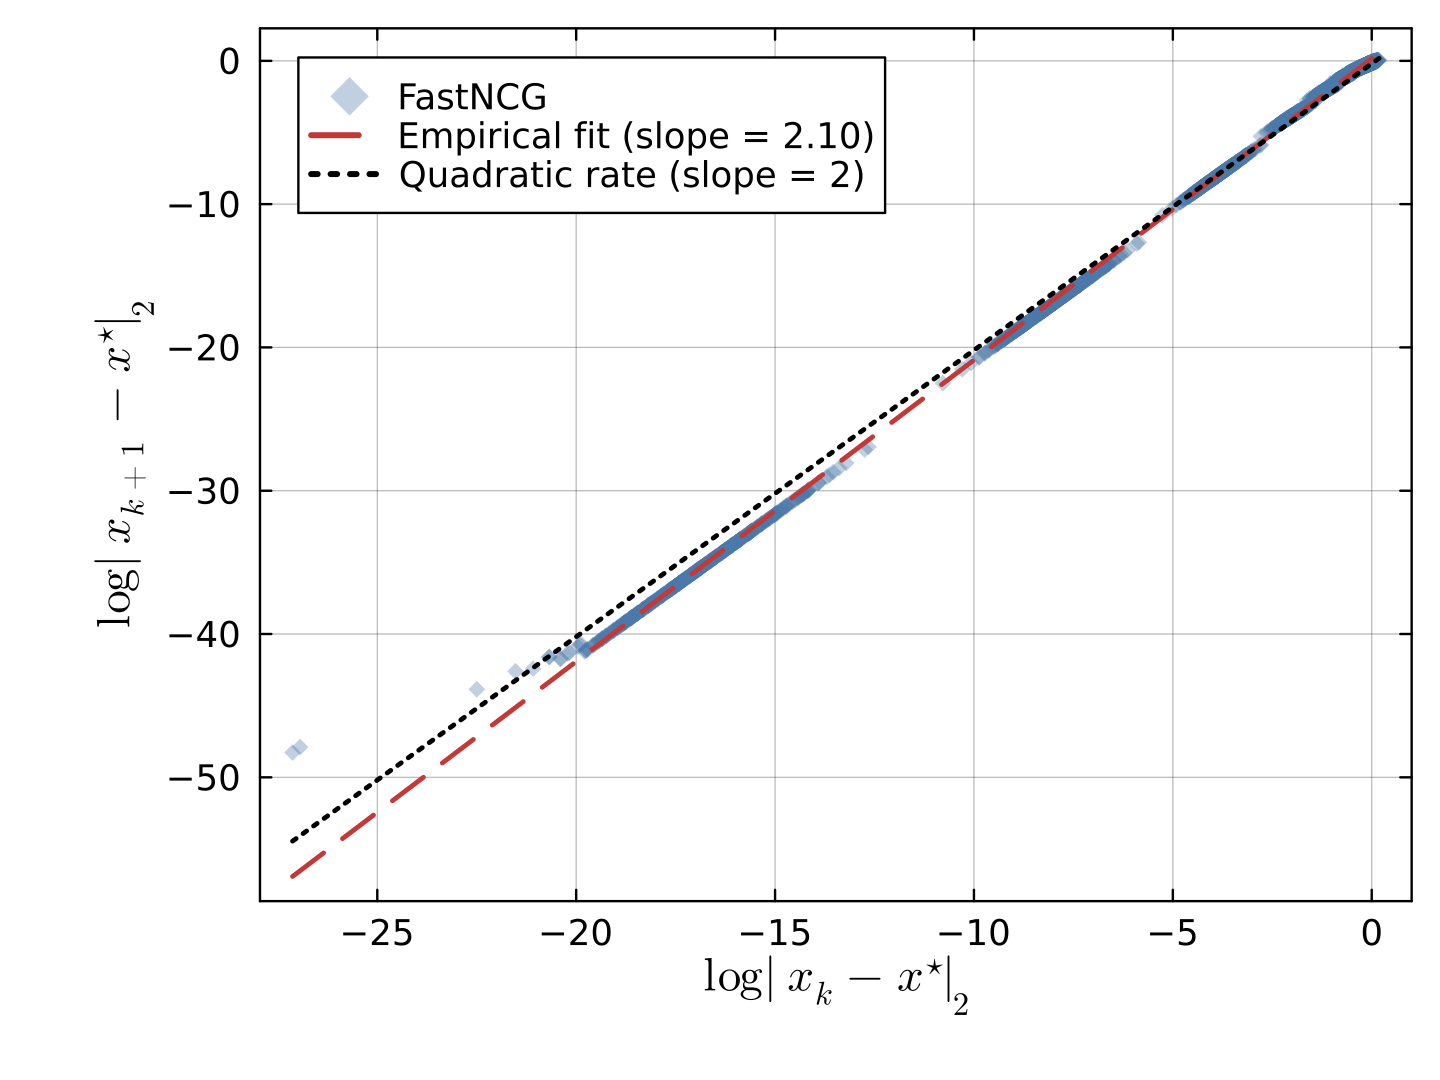

(runs = NamedTuple[(errors = [1.0515732878409083, 0.9421986292484532, 0.823270398554583, 0.7002921766668375, 0.554788971638137, 0.3567251675380283, 0.1511288357244264, 0.025877011031439925, 0.0005085728428949819, 1.0066373516252982e-7, 1.971542358940251e-15], losses = [0.0321387035766515, 0.014476861134095933, 0.006654356055260597, 0.0033418185212313618, 0.001713150808655008, 0.0006523056690328428, 0.00011455360831415813, 3.3483550025682494e-6, 1.2932317192944022e-9, 5.066593788435978e-17, 1.9434896365478438e-32], gradients = [0.15923352718876507, 0.0691274551128086, 0.030080601097121663, 0.013618339594679427, 0.006981404743263249, 0.0037534910830317025, 0.001520699023554646, 0.00025880976417866927, 5.085728717152261e-6, 1.0066373516253004e-9, 1.9715423589402508e-17], status = :first_order, iterations = 10, hvp = 10, x = [2.5786187617315713e-16, 1.3461924078342402e-16, 1.332241841367411e-16, 9.30798864365973e-17, 4.1518924640057884e-17, 1.5915170383351761e-16, 1.997007608597183e-16, 4.

In [2]:
include("experiments/strongly_convex.jl")
StronglyConvexExperiment.run_experiment()


In [2]:
include("benchmark/benchmark.jl")
rows = main()


Formal optimizer benchmark
Methods: ARCqK, FastNCG, GD, NAG, CR, ANCG, ARNCG
BenchmarkTools protocol: seconds=5.0, evals=1
Tolerance: 1.0e-7

Problem: Rosenbrock (dim=1000)
  ARCqK    deterministic run ... iter=2193 HVP=23196 f=3.39342e-19 |g|=8.8283e-09 [CONVERGED]
  ARCqK    benchmark ... median=0.88556 s  Q25=0.88241  Q75=0.88710  samples=6
  FastNCG  deterministic run ... iter=2517 HVP=15149 f=1.47146e-22 |g|=4.1313e-10 [CONVERGED]
  FastNCG  benchmark ... median=0.07962 s  Q25=0.07941  Q75=0.07995  samples=63
  GD       deterministic run ... iter=10000 HVP=0 f=9.99000e+02 |g|=6.3214e+01 [NOT CONVERGED]
  GD       benchmark ... median=0.03214 s  Q25=0.03190  Q75=0.03244  samples=155
  NAG      deterministic run ... iter=10000 HVP=0 f=9.98994e+02 |g|=6.3194e+01 [NOT CONVERGED]
  NAG      benchmark ... median=0.08005 s  Q25=0.07961  Q75=0.08049  samples=63
  CR       deterministic run ... iter=1411 HVP=1410000 f=4.98748e-17 |g|=5.6405e-08 [CONVERGED]
  CR       benchmark ... median=9

28-element Vector{NamedTuple}:
 (problem = "Rosenbrock", method = "ARCqK", median = 0.8855568545, q25 = 0.88241460425, q75 = 0.8871001355, iqr = 0.00468553125, samples = 6, iter = 2193, hvp = 23196, nobj = 2193, ngrad = 1491, f = 3.3934208803672343e-19, g = 8.828285206587087e-9, status = "CONVERGED", details = NamedTuple())
 (problem = "Rosenbrock", method = "FastNCG", median = 0.07962275, q25 = 0.0794146465, q75 = 0.079951875, iqr = 0.0005372285, samples = 63, iter = 2517, hvp = 15149, nobj = 7567, ngrad = 7567, f = 1.4714557568952127e-22, g = 4.1312684306971754e-10, status = "CONVERGED", details = NamedTuple())
 (problem = "Rosenbrock", method = "GD", median = 0.032142083, q25 = 0.031903959, q75 = 0.0324417295, iqr = 0.0005377705, samples = 155, iter = 10000, hvp = 0, nobj = 20043, ngrad = 10001, f = 998.9999921872032, g = 63.213897576070565, status = "NOT CONVERGED", details = NamedTuple())
 (problem = "Rosenbrock", method = "NAG", median = 0.080050666, q25 = 0.079605021, q75 = 0.08

In [5]:
using Printf

function comma_int(n::Integer)
    s = string(n)
    parts = String[]
    while length(s) > 3
        pushfirst!(parts, s[end-2:end])
        s = s[1:end-3]
    end
    pushfirst!(parts, s)
    join(parts, "{,}")
end

function sci(x; digits=2)
    x == 0 && return "0"
    e = floor(Int, log10(abs(x)))
    a = x / 10.0^e
    @sprintf("%.*f\$\\times10^{%d}\$", digits, a, e)
end

function loss_string(problem, x)
    problem == "LogSumExp" && return @sprintf("%.4f", x)
    problem == "TRegression" && return @sprintf("%.2f", x)
    problem in ("Rosenbrock", "Polytope") && return sci(x)
    @sprintf("%.4f", x)
end

function caption(problem)
    problem == "Rosenbrock" &&
        return "Performance comparison on the Rosenbrock function (\$q=1{,}000\$)."
    problem == "LogSumExp" &&
        return "Performance comparison on the LogSumExp problem."
    problem == "Polytope" &&
        return "Performance comparison on the Polytope problem."
    problem == "TRegression" &&
        return "Performance comparison on the Student \$t\$ regression problem with \$d=200\$, \$m=500\$, and \$\\nu=0.01\$."
    "Performance comparison on the $(problem) problem."
end

function table_label(problem)
    Dict(
        "Rosenbrock"  => "tab:rosenbrock",
        "LogSumExp"   => "tab:logsumexp",
        "Polytope"    => "tab:polytope",
        "TRegression" => "tab:student_t",
    )[problem]
end

function latex_table(results, problem; io=stdout)
    rows = filter(r -> r.problem == problem, results)
    isempty(rows) && return

    # Fixed order used in the paper
    method_order = ["FastNCG", "ANCG", "ARNCG", "ARCqK", "GD", "NAG", "CR"]
    order = Dict(m => i for (i, m) in enumerate(method_order))
    sort!(rows, by=r -> get(order, r.method, typemax(Int)))

    base = only(filter(r -> r.method == "FastNCG", rows)).median

    println(io, "\\begin{table}[htbp]")
    println(io, "\\centering")
    println(io, "\\caption{$(caption(problem))}")
    println(io, "\\label{$(table_label(problem))}")
    println(io, "\\begin{tabular}{lrrrrrr}")
    println(io, "\\toprule")
    println(io, "\\textbf{Algorithm} & \\textbf{Time (s)} & \\textbf{Rel Time} & \\textbf{HVP} & \\textbf{Iter} & \$\\|\\nabla f(\\bx_n)\\|\$ & \\textbf{Final Loss} \\\\")
    println(io, "\\midrule")

    for r in rows
        isfast = r.method == "FastNCG"
        time = @sprintf("%.3f", r.median)
        rel = @sprintf("%.2f", r.median / base) * "\$\\times\$"
        hvp = r.hvp == 0 ? "-" : comma_int(r.hvp)
        iter = comma_int(r.iter)
        grad = sci(r.g)
        loss = loss_string(problem, r.f)

        vals = [r.method, time, rel, hvp, iter, grad, loss]

        if isfast
            # Bold FastNCG performance entries, but keep final loss unbolded
            vals[1:6] = ["\\textbf{$v}" for v in vals[1:6]]
        end

        println(io, join(vals, " & "), " \\\\")
    end

    println(io, "\\bottomrule")
    println(io, "\\end{tabular}")
    println(io, "\\end{table}")
end

function latex_tables(results; io=stdout)
    for (i, problem) in enumerate(
        ["Rosenbrock", "LogSumExp", "Polytope", "TRegression"]
    )
        i > 1 && println(io, "\n")
        latex_table(results, problem; io)
    end
end

latex_tables(rows)


\begin{table}[htbp]
\centering
\caption{Performance comparison on the Rosenbrock function ($q=1{,}000$).}
\label{tab:rosenbrock}
\begin{tabular}{lrrrrrr}
\toprule
\textbf{Algorithm} & \textbf{Time (s)} & \textbf{Rel Time} & \textbf{HVP} & \textbf{Iter} & $\|\nabla f(\bx_n)\|$ & \textbf{Final Loss} \\
\midrule
\textbf{FastNCG} & \textbf{0.080} & \textbf{1.00$\times$} & \textbf{15{,}149} & \textbf{2{,}517} & \textbf{4.13$\times10^{-10}$} & 1.47$\times10^{-22}$ \\
ANCG & 15.032 & 188.78$\times$ & 1{,}773{,}208 & 1{,}677 & 2.04$\times10^{-8}$ & 4.13$\times10^{-16}$ \\
ARNCG & 0.296 & 3.72$\times$ & 46{,}202 & 1{,}642 & 1.59$\times10^{-8}$ & 2.47$\times10^{-16}$ \\
ARCqK & 0.886 & 11.12$\times$ & 23{,}196 & 2{,}193 & 8.83$\times10^{-9}$ & 3.39$\times10^{-19}$ \\
GD & 0.032 & 0.40$\times$ & - & 10{,}000 & 6.32$\times10^{1}$ & 9.99$\times10^{2}$ \\
NAG & 0.080 & 1.01$\times$ & - & 10{,}000 & 6.32$\times10^{1}$ & 9.99$\times10^{2}$ \\
CR & 91.414 & 1148.09$\times$ & 1{,}410{,}000 & 1{,}411 & 5

In [2]:
include("test/test.jl")

SRN-CG clean GitHub build: regression check against frozen production reference
Problem             Iter       HVP       Obj      Grad         f(x*)       |g(x*)|    Time(s)     Status
--------------------------------------------------------------------------------------------------------------
Rosenbrock          2517     15148      7566      7566    3.1735e-24    3.5932e-11     0.0867       PASS
LogSumExp             54       419       206       206    1.4623e+00    8.3587e-08     0.0350       PASS
Polytope              51        98       112       112    9.2304e-12    4.6573e-08     0.0118       PASS
TRegression          193      1230       708       708    1.3904e+03    2.5086e-08     0.0529       PASS
--------------------------------------------------------------------------------------------------------------
PASS.


In [ ]:
rows

## Plots

In [3]:
using FastNCG
using LinearAlgebra, Printf, NLPModels, BenchmarkTools, Statistics

const TAUS = collect(0.05:0.05:0.95)

function build_problems()
    return (
        (
            name = "Rosenbrock",
            build = () -> make_rosenbrock(100; x0=zeros(100)),
        ),
        (
            name = "LogSumExp",
            build = () -> make_logsumexp(200, 1000, 0.05; seed=42, x0=zeros(200)),
        ),
        (
            name = "Polytope",
            build = () -> make_polytope(400, 1000, 3; seed=42, x0=ones(400)),
        ),
        (
            name = "TRegression",
            build = () -> make_tregression(200, 500, 0.01; seed=42),
        ),
    )
end

function make_solver(p, τ)
    x0, f, g, hv, objdiff = p.build()

    nlp = FastNCG.ClosureNLPModel(
        x0, f, g, hv;
        objdiff_fn=objdiff,
        name=p.name,
    )

    solver = FastNCG.FastNCGSolver(
        sigma_0_ref=1.0,
        rho=2.0,
        beta=0.25,
        gamma=1e-3,
        tau=τ,
        max_krylov=100,
        max_outer=10000,
        max_regularization_retries=50,
    )

    return nlp, solver, x0
end

function solve_once(p, τ)
    nlp, solver, x0 = make_solver(p, τ)

    FastNCG.optimize!(
        solver, nlp;
        initial_theta=x0,
        max_iter=10000,
        tol=1e-7,
    )

    return solver
end

function benchmark_tau(p, τ)
    stat_solver = solve_once(p, τ)
    elapsed = NaN

    if stat_solver.status == :first_order
        trial = @benchmark FastNCG.optimize!(
            solver, nlp;
            initial_theta=x0,
            max_iter=10000,
            tol=1e-7,
        ) setup=begin
            nlp, solver, x0 = make_solver($p, $τ)
        end evals=1 samples=50 seconds=10

        elapsed = median(trial).time / 1e9
    end

    return (
        hvp=stat_solver.hvp_count,
        iter=length(stat_solver.loss_history)-1,
        loss=last(stat_solver.loss_history),
        gnorm=last(stat_solver.grad_norm_history),
        retries=stat_solver.ratio_increases,
        status=stat_solver.status,
        time=elapsed,
    )
end

function main()
    @printf("%-14s %6s %8s %8s %14s %12s %8s %12s %15s\n",
            "Problem", "tau", "HVP", "Iter", "Loss",
            "|g|", "Retries", "Time(s)", "Status")

    results = NamedTuple[]

    for p in build_problems(), τ in TAUS
        r = benchmark_tau(p, τ)

        push!(results, (
            problem=p.name,
            tau=τ,
            r...,
        ))

        @printf("%-14s %6.2f %8d %8d %14.6e %12.3e %8d %12.6f %15s\n",
                p.name, τ, r.hvp, r.iter, r.loss,
                r.gnorm, r.retries, r.time, string(r.status))
    end

    return results
end

results = main()

Problem           tau      HVP     Iter           Loss          |g|  Retries      Time(s)          Status
Rosenbrock       0.05     1475      251   1.197146e-26    3.296e-12      249     0.001439     first_order
Rosenbrock       0.10     1567      256   3.905517e-20    6.835e-09      253     0.001460     first_order
Rosenbrock       0.15     1549      236   2.690865e-25    7.326e-12      232     0.001578     first_order
Rosenbrock       0.20     1400      190   3.846511e-20    7.500e-09      186     0.001447     first_order
Rosenbrock       0.25     1348      165   4.752829e-18    2.299e-08      161     0.001426     first_order
Rosenbrock       0.30     1282      151   2.693057e-19    1.359e-08      147     0.001324     first_order
Rosenbrock       0.35     1324      149   1.107980e-28    4.322e-13      157     0.001533     first_order
Rosenbrock       0.40     1333      150   2.602181e-17    6.069e-08      146     0.001376     first_order
Rosenbrock       0.45     1372      151   2.93

76-element Vector{NamedTuple}:
 (problem = "Rosenbrock", tau = 0.05, hvp = 1475, iter = 251, loss = 1.1971457274794617e-26, gnorm = 3.2958925239613583e-12, retries = 249, status = :first_order, time = 0.0014393545)
 (problem = "Rosenbrock", tau = 0.1, hvp = 1567, iter = 256, loss = 3.9055170927601885e-20, gnorm = 6.835298068115405e-9, retries = 253, status = :first_order, time = 0.001459604)
 (problem = "Rosenbrock", tau = 0.15, hvp = 1549, iter = 236, loss = 2.690865437909993e-25, gnorm = 7.326398648140452e-12, retries = 232, status = :first_order, time = 0.0015782705)
 (problem = "Rosenbrock", tau = 0.2, hvp = 1400, iter = 190, loss = 3.8465110281696416e-20, gnorm = 7.499805648765141e-9, retries = 186, status = :first_order, time = 0.001446625)
 (problem = "Rosenbrock", tau = 0.25, hvp = 1348, iter = 165, loss = 4.7528292412660986e-18, gnorm = 2.2993674889174126e-8, retries = 161, status = :first_order, time = 0.001426229)
 (problem = "Rosenbrock", tau = 0.3, hvp = 1282, iter = 151, 

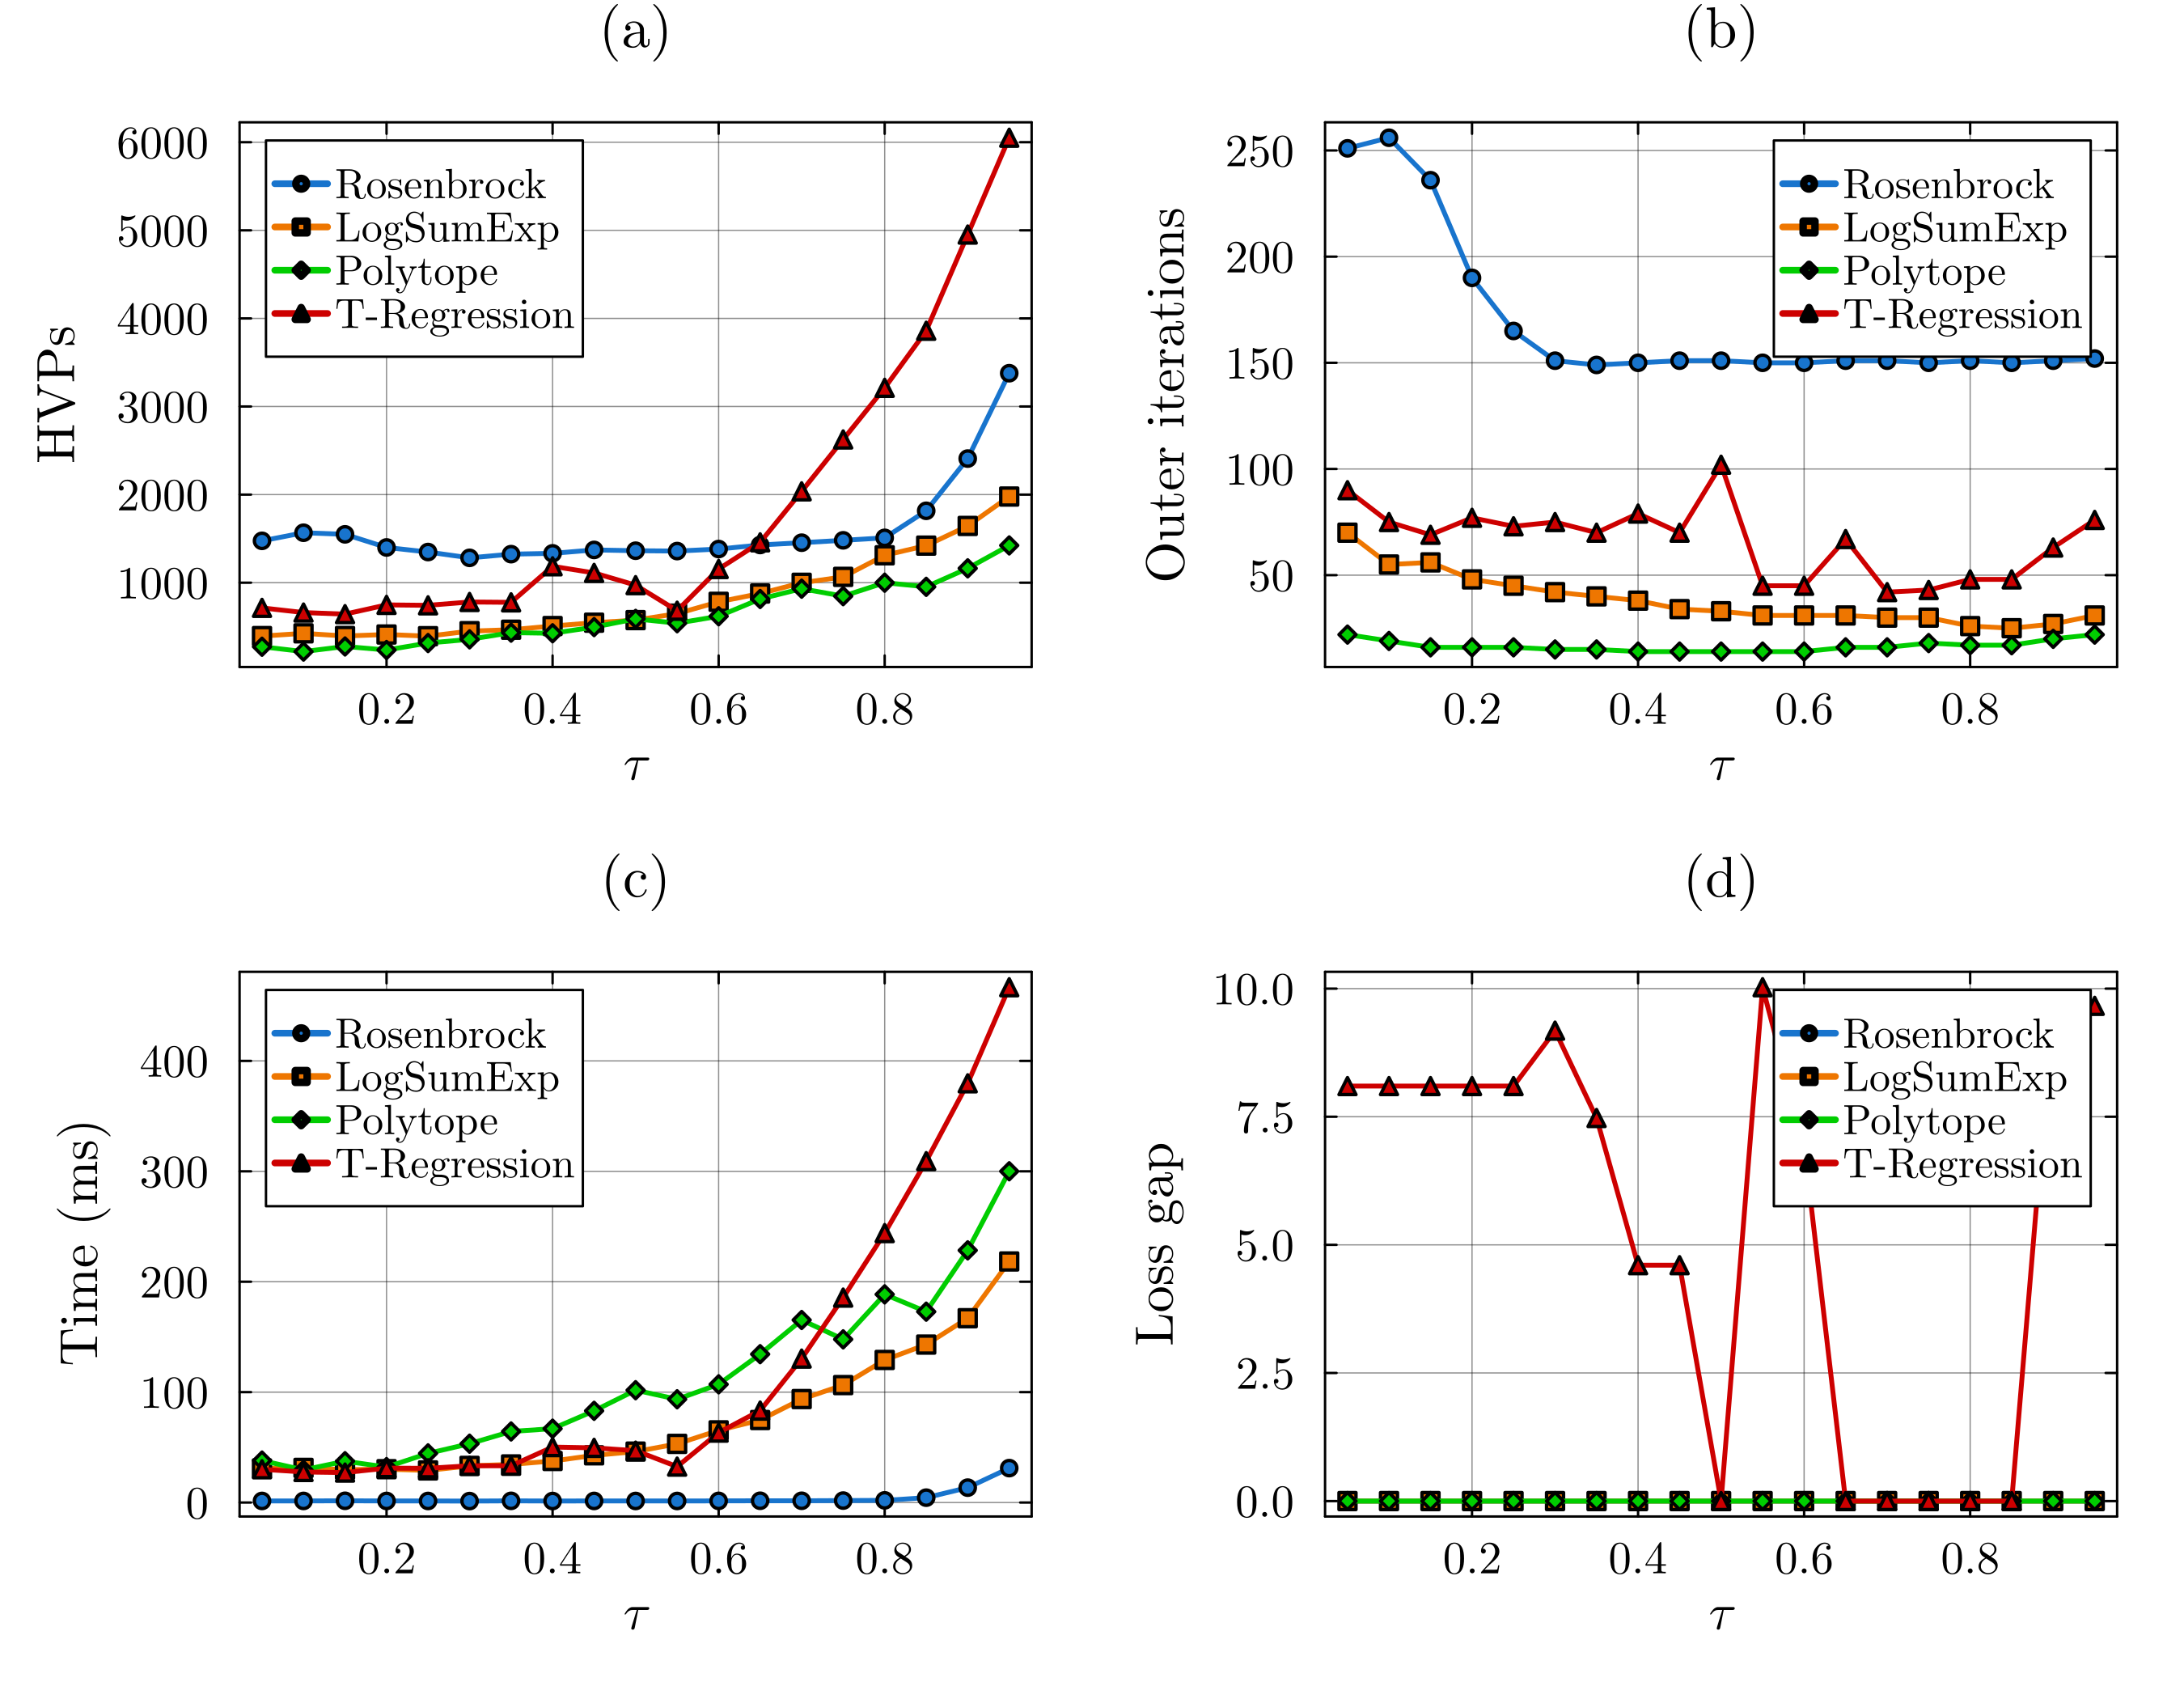

"/Users/caleblee/codes/Julia/MyPack/FastNCG/tau_sensitivity.pdf"

In [4]:
using Plots
using LaTeXStrings

rosen = filter(r -> r.problem == "Rosenbrock", results)
lse   = filter(r -> r.problem == "LogSumExp", results)
poly  = filter(r -> r.problem == "Polytope", results)
treg  = filter(r -> r.problem == "TRegression", results)

sort!(rosen, by=r -> r.tau)
sort!(lse, by=r -> r.tau)
sort!(poly, by=r -> r.tau)
sort!(treg, by=r -> r.tau)

τ = getfield.(rosen, :tau)

colors = [:dodgerblue3, :darkorange2, :green3, :red3]

default(
    fontfamily="Computer Modern",
    linewidth=2,
    markersize=3.5,
    guidefontsize=14,
    tickfontsize=12,
    titlefontsize=15,
    legendfontsize=11,
    framestyle=:box,
    grid=true,
    gridalpha=0.25
)

# (a) HVPs
p1 = plot(τ, getfield.(rosen, :hvp);
    marker=:circle, color=colors[1], label="Rosenbrock",
    xlabel=L"\tau", ylabel="HVPs", title="(a)", legend=:topleft)
plot!(p1, τ, getfield.(lse, :hvp);
    marker=:square, color=colors[2], label="LogSumExp")
plot!(p1, τ, getfield.(poly, :hvp);
    marker=:diamond, color=colors[3], label="Polytope")
plot!(p1, τ, getfield.(treg, :hvp);
    marker=:utriangle, color=colors[4], label="T-Regression")

# (b) Outer iterations
p2 = plot(τ, getfield.(rosen, :iter);
    marker=:circle, color=colors[1], label="Rosenbrock",
    xlabel=L"\tau", ylabel="Outer iterations", title="(b)", legend=:topright)
plot!(p2, τ, getfield.(lse, :iter);
    marker=:square, color=colors[2], label="LogSumExp")
plot!(p2, τ, getfield.(poly, :iter);
    marker=:diamond, color=colors[3], label="Polytope")
plot!(p2, τ, getfield.(treg, :iter);
    marker=:utriangle, color=colors[4], label="T-Regression")

# (c) Wall-clock time
p3 = plot(τ, 1000 .* getfield.(rosen, :time);
    marker=:circle, color=colors[1], label="Rosenbrock",
    xlabel=L"\tau", ylabel="Time (ms)", title="(c)", legend=:topleft)
plot!(p3, τ, 1000 .* getfield.(lse, :time);
    marker=:square, color=colors[2], label="LogSumExp")
plot!(p3, τ, 1000 .* getfield.(poly, :time);
    marker=:diamond, color=colors[3], label="Polytope")
plot!(p3, τ, 1000 .* getfield.(treg, :time);
    marker=:utriangle, color=colors[4], label="T-Regression")

# (d) Final loss gap
loss_rosen = getfield.(rosen, :loss)
loss_lse   = getfield.(lse, :loss)
loss_poly  = getfield.(poly, :loss)
loss_treg  = getfield.(treg, :loss)

Δrosen = loss_rosen .- minimum(loss_rosen)
Δlse   = loss_lse   .- minimum(loss_lse)
Δpoly  = loss_poly  .- minimum(loss_poly)
Δtreg  = loss_treg  .- minimum(loss_treg)

p4 = plot(τ, Δrosen;
    marker=:circle, color=colors[1], label="Rosenbrock",
    xlabel=L"\tau", ylabel="Loss gap", title="(d)", legend=:topright)
plot!(p4, τ, Δlse;
    marker=:square, color=colors[2], label="LogSumExp")
plot!(p4, τ, Δpoly;
    marker=:diamond, color=colors[3], label="Polytope")
plot!(p4, τ, Δtreg;
    marker=:utriangle, color=colors[4], label="T-Regression")

p = plot(
    p1, p2, p3, p4;
    layout=(2,2),
    size=(900,700),
    dpi=300,
    margin=5Plots.mm
)

display(p)
savefig(p, "tau_sensitivity.pdf")
# savefig(p, "tau_sensitivity.png")